# Отрисовка дя визуальной проверки

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import base64
from io import BytesIO

plt.style.use('dark_background')

df = pd.read_csv('dataset.csv') 

# Считаем среднее и отклонение по всему датасету
axes = ['ax', 'ay', 'az', 'gx', 'gy', 'gz']
for col in axes:
    mean_val = df[col].mean()
    std_val = df[col].std()
    df[col] = (df[col] - mean_val) / (std_val + 1e-6)

TARGET_LABEL = 0  # 1 - Telegram, 2 - Spotify, 3 - Круг, 0 - Шум

class_df = df[df['label'] == TARGET_LABEL]
gesture_ids = class_df['gesture_id'].unique()

html = f"""
<!DOCTYPE html>
<html>
<head>
    <meta charset="utf-8">
    <title>Класс {TARGET_LABEL}</title>
    <style>
        body {{ background-color: #111; color: white; font-family: sans-serif; padding: 20px; }}
        h1 {{ text-align: center; color: #eccc68; margin-bottom: 30px; }}
        .grid {{ display: grid; grid-template-columns: repeat(auto-fill, minmax(250px, 1fr)); gap: 20px; }}
        .card {{ background: #222; border-radius: 10px; padding: 15px; text-align: center; box-shadow: 0 4px 6px rgba(0,0,0,0.3); }}
        .id-label {{ font-size: 28px; font-weight: bold; color: #ff4757; margin-bottom: 10px; }}
        img {{ max-width: 100%; border-radius: 5px; }}
    </style>
</head>
<body>
    <h1>Класс {TARGET_LABEL} (Z-Score Normalized)</h1>
    <div class="grid">
"""

for gid in gesture_ids:
    group = class_df[class_df['gesture_id'] == gid]
    
    acc_x = group['ax'].rolling(1, min_periods=1).mean()
    acc_y = group['ay'].rolling(1, min_periods=1).mean()
    acc_z = group['az'].rolling(1, min_periods=1).mean()

    gyr_x = group['gx'].rolling(1, min_periods=1).mean()
    gyr_y = group['gy'].rolling(1, min_periods=1).mean()
    gyr_z = group['gz'].rolling(1, min_periods=1).mean()
    
    fig, ax = plt.subplots(figsize=(4, 3))
    
    # Акселерометр - сплошные
    ax.plot(acc_x.values, color='#ff4757', linewidth=1) # X - красный
    ax.plot(acc_y.values, color='#2ed573', linewidth=1) # Y - зеленый
    ax.plot(acc_z.values, color='#1e90ff', linewidth=1) # Z - синий
    
    # Гироскоп - пунктир
    ax.plot(gyr_x.values, color='#ff4757', linewidth=1, linestyle='--') # X - красный
    ax.plot(gyr_y.values, color='#2ed573', linewidth=1, linestyle='--') # Y - зеленый
    ax.plot(gyr_z.values, color='#1e90ff', linewidth=1, linestyle='--') # Z - синий
    
    ax.axis('off') # Выключаем оси, оставляем только чистый паттерн
    
    plt.tight_layout()
    
    buf = BytesIO()
    plt.savefig(buf, format='png', facecolor='#222', bbox_inches='tight')
    plt.close(fig)
    img_base64 = base64.b64encode(buf.getbuffer()).decode("ascii")
    
    html += f"""
        <div class="card">
            <div class="id-label">ID: {gid}</div>
            <img src="data:image/png;base64,{img_base64}">
        </div>
    """

html += """
    </div>
</body>
</html>
"""

with open('gallery.html', 'w', encoding='utf-8') as f:
    f.write(html)

# Очистка от мусора

In [10]:
trash_ids = [] # удалить откровенно корявые после пробежки глазками

df_clean = df[~df['gesture_id'].isin(trash_ids)]

# Считаем уникальные идентификаторы жестов
gestures_before = df['gesture_id'].nunique()
gestures_after = df_clean['gesture_id'].nunique()

print(f"Было измерений (жестов): {gestures_before}")
print(f"Осталось измерений (жестов): {gestures_after}")

# Сохраняем чистый датасет
df_clean.to_csv('dataset_mobile_CLEAN.csv', index=False)

Было измерений (жестов): 363
Осталось измерений (жестов): 363


# Аугментация

In [ ]:
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter1d

df = pd.read_csv('dataset_mobile_CLEAN.csv')

augmented_rows = []
new_gesture_id = 0

NOISE_LEVEL_ACC = 0.5 
NOISE_LEVEL_GYR = 0.1 
SHIFT_MAX = 20     

def add_to_dataset(ax, ay, az, gx, gy, gz, label, gid):
    for i in range(len(ax)):
        augmented_rows.append({
            'ax': ax[i], 'ay': ay[i], 'az': az[i], 
            'gx': gx[i], 'gy': gy[i], 'gz': gz[i],
            'label': label, 'gesture_id': gid
        })

for gid, group in df.groupby('gesture_id'):
    label = group['label'].iloc[0]
    
    ax_raw = group['ax'].values
    ay_raw = group['ay'].values
    az_raw = group['az'].values
    gx_raw = group['gx'].values
    gy_raw = group['gy'].values
    gz_raw = group['gz'].values
    n_samples = len(ax_raw)
    
    # 0. Убираю фон
    base_len = 10
    ax = ax_raw - np.mean(ax_raw[:base_len])
    ay = ay_raw - np.mean(ay_raw[:base_len])
    az = az_raw - np.mean(az_raw[:base_len])
    gx = gx_raw - np.mean(gx_raw[:base_len])
    gy = gy_raw - np.mean(gy_raw[:base_len])
    gz = gz_raw - np.mean(gz_raw[:base_len])
    
    # Шум 
    # Амплитуда = NOISE_LEVEL. Сглаживание слабое (sigma=1.5), имитирует тремор.
    dyn_noise_acc = lambda: np.random.normal(0, NOISE_LEVEL_ACC, n_samples) + gaussian_filter1d(np.random.normal(0, NOISE_LEVEL_ACC, n_samples), sigma=1.5)
    dyn_noise_gyr = lambda: np.random.normal(0, NOISE_LEVEL_GYR, n_samples) + gaussian_filter1d(np.random.normal(0, NOISE_LEVEL_GYR, n_samples), sigma=1.5)
    
    # Шум для замещения сдвига
    # Амплитуда = 30% . Сглаживание сильное (sigma=4.0), имитирует медленный дрейф.
    bg_noise_acc = lambda: gaussian_filter1d(np.random.normal(0, NOISE_LEVEL_ACC * 0.3, n_samples), sigma=4.0)
    bg_noise_gyr = lambda: gaussian_filter1d(np.random.normal(0, NOISE_LEVEL_GYR * 0.3, n_samples), sigma=4.0)

    # ==========================================

    # 1. ОРИГИНАЛ (Чистый, с вычетом фона)
    add_to_dataset(ax, ay, az, gx, gy, gz, label, new_gesture_id)
    new_gesture_id += 1
    
    # 2. ШУМ В ДВИЖЕНИИ (Добавляем шум поверх оригинального сигнала)
    add_to_dataset(ax + dyn_noise_acc(), ay + dyn_noise_acc(), az + dyn_noise_acc(), 
                   gx + dyn_noise_gyr(), gy + dyn_noise_gyr(), gz + dyn_noise_gyr(), label, new_gesture_id)
    new_gesture_id += 1
    
    # 3. МАСШТАБ
    scale_factor = np.random.uniform(0.7, 1.3)
    add_to_dataset(ax * scale_factor, ay * scale_factor, az * scale_factor, 
                   gx * scale_factor, gy * scale_factor, gz * scale_factor, label, new_gesture_id)
    new_gesture_id += 1
    
    # 4. СДВИГ ПО ВРЕМЕНИ (Пустоты заливаем тихим фоновым шумом)
    shift = np.random.randint(-SHIFT_MAX, SHIFT_MAX)
    
    if shift != 0:
        ax_shift, ay_shift, az_shift = bg_noise_acc(), bg_noise_acc(), bg_noise_acc()
        gx_shift, gy_shift, gz_shift = bg_noise_gyr(), bg_noise_gyr(), bg_noise_gyr()
        
        abs_shift = abs(shift)
        if shift > 0:
            ax_shift[shift:] = ax[:-shift]
            ay_shift[shift:] = ay[:-shift]
            az_shift[shift:] = az[:-shift]
            gx_shift[shift:] = gx[:-shift]
            gy_shift[shift:] = gy[:-shift]
            gz_shift[shift:] = gz[:-shift]
        else:
            ax_shift[:-abs_shift] = ax[abs_shift:]
            ay_shift[:-abs_shift] = ay[abs_shift:]
            az_shift[:-abs_shift] = az[abs_shift:]
            gx_shift[:-abs_shift] = gx[abs_shift:]
            gy_shift[:-abs_shift] = gy[abs_shift:]
            gz_shift[:-abs_shift] = gz[abs_shift:]
            
        add_to_dataset(ax_shift, ay_shift, az_shift, gx_shift, gy_shift, gz_shift, label, new_gesture_id)
        new_gesture_id += 1
    else:
        add_to_dataset(ax.copy(), ay.copy(), az.copy(), gx.copy(), gy.copy(), gz.copy(), label, new_gesture_id)
        new_gesture_id += 1

df_aug = pd.DataFrame(augmented_rows)
df_aug.to_csv('dataset_AUGMENTED.csv', index=False)

print(f"Исходных жестов: {len(df['gesture_id'].unique())}")
print(f"После аугментации: {len(df_aug['gesture_id'].unique())}")

Исходных жестов: 363
После аугментации: 1452
Файл dataset_AUGMENTED.csv готов!


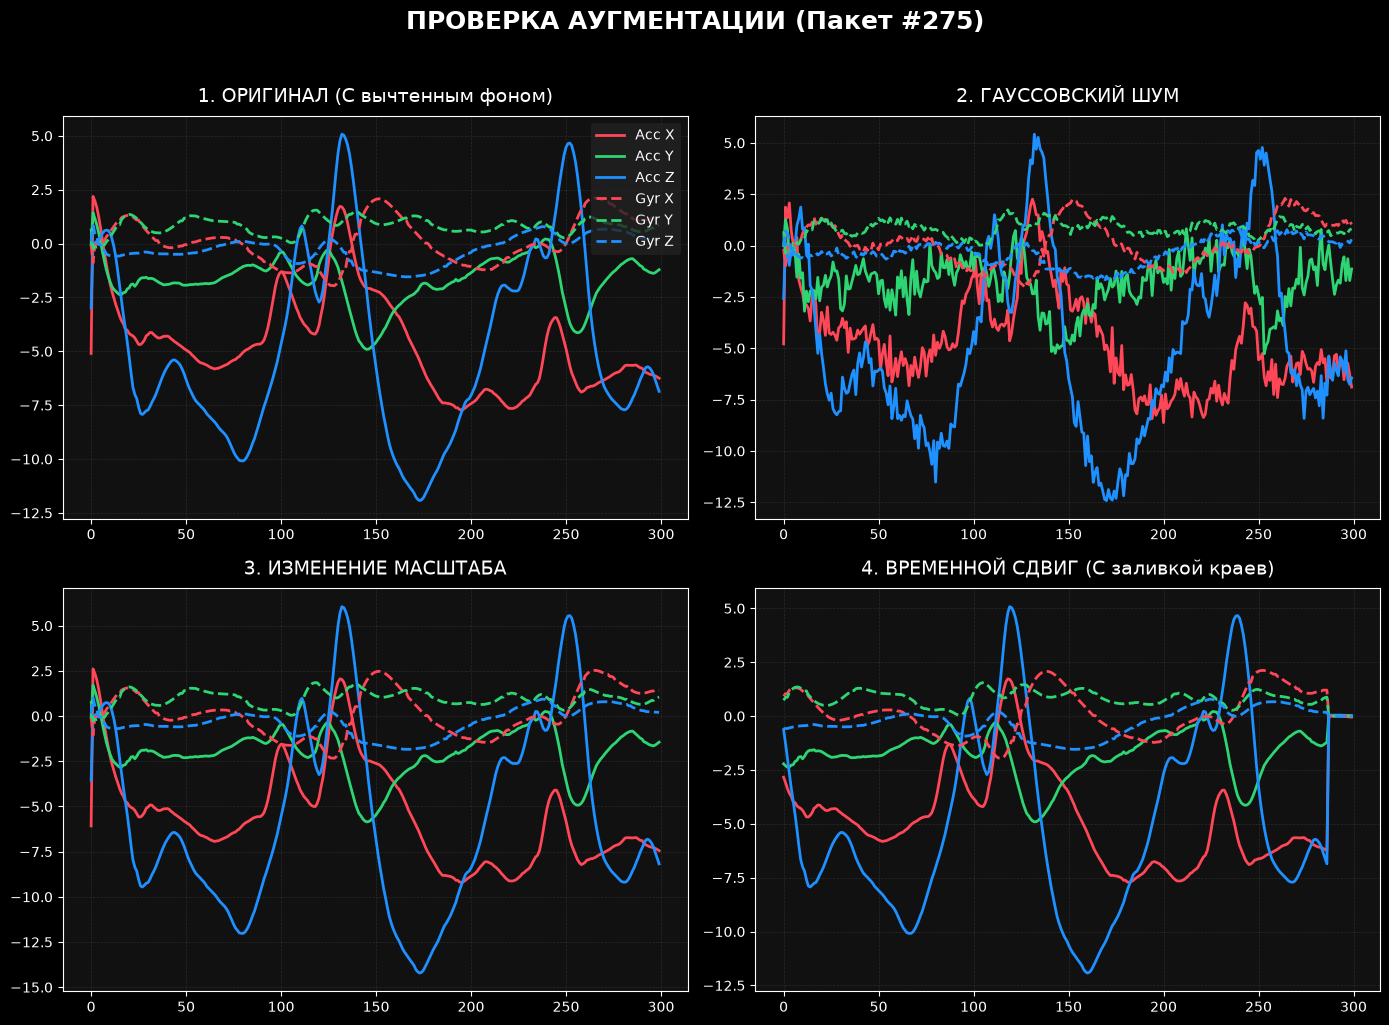

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import random

# Темная тема
plt.style.use('dark_background')

# Загружаем аугментации
df_aug = pd.read_csv('dataset_AUGMENTED.csv')

total_original_gestures = len(df_aug['gesture_id'].unique()) // 4

rand_idx = random.randint(0, total_original_gestures - 1)

base_id = rand_idx * 4
ids_to_plot = [base_id, base_id + 1, base_id + 2, base_id + 3]
titles = [
    '1. ОРИГИНАЛ (С вычтенным фоном)', 
    '2. ГАУССОВСКИЙ ШУМ', 
    '3. ИЗМЕНЕНИЕ МАСШТАБА', 
    '4. ВРЕМЕННОЙ СДВИГ (С заливкой краев)'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f'ПРОВЕРКА АУГМЕНТАЦИИ (Пакет #{rand_idx})', fontsize=18, fontweight='bold', y=1.02)

for i, ax in enumerate(axes.flatten()):
    group = df_aug[df_aug['gesture_id'] == ids_to_plot[i]]
    if group.empty:
        continue
        
    ax.plot(group['ax'].values, color='#ff4757', linewidth=2, label='Acc X')
    ax.plot(group['ay'].values, color='#2ed573', linewidth=2, label='Acc Y')
    ax.plot(group['az'].values, color='#1e90ff', linewidth=2, label='Acc Z')
    ax.plot(group['gx'].values, color='#ff4757', linewidth=2, linestyle='--', label='Gyr X')
    ax.plot(group['gy'].values, color='#2ed573', linewidth=2, linestyle='--', label='Gyr Y')
    ax.plot(group['gz'].values, color='#1e90ff', linewidth=2, linestyle='--', label='Gyr Z')
    
    ax.set_title(titles[i], color='white', fontsize=14, pad=10)
    
    # Сетка для наглядности
    ax.grid(color='#444', linestyle='--', linewidth=0.5, alpha=0.5)
    ax.set_facecolor('#111')
    
    if i == 0:
        ax.legend(loc='upper right', frameon=True, facecolor='#222', edgecolor='none')

plt.tight_layout()
plt.show()

In [ ]:
class EdgeCNN_v6(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(in_channels=6, out_channels=16, kernel_size=15, stride=2, padding=7),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2, stride=2),
            
            nn.Conv1d(in_channels=16, out_channels=32, kernel_size=5, stride=2, padding=2),
            nn.BatchNorm1d(32),
            nn.ReLU()
        )
        self.gap = nn.AdaptiveAvgPool1d(1) 
        self.classifier = nn.Linear(32, num_classes)
        
    def forward(self, x):
        x = self.features(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)

model = EdgeCNN_v6(num_classes=4)

In [ ]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit

df = pd.read_csv('dataset_AUGMENTED.csv') 

gesture_ids = df['gesture_id'].unique()
X_list, y_list, group_list = [], [], []

for gid in gesture_ids:
    group_data = df[df['gesture_id'] == gid]
    label = group_data['label'].iloc[0]
    
    # Группируем оригиналы и их 3 аугментированные копии вместе
    base_original_id = gid // 4 
    
    ax = group_data['ax'].values
    ay = group_data['ay'].values
    az = group_data['az'].values
    gx = group_data['gx'].values
    gy = group_data['gy'].values
    gz = group_data['gz'].values
    
    features = np.vstack([ax, ay, az, gx, gy, gz])

    #1.5 секунды при 200 Гц = 300 точек
    if features.shape[1] > 300:
        features = features[:, :300]
    elif features.shape[1] < 300:
        pad_width = 300 - features.shape[1]
        features = np.pad(features, ((0, 0), (0, pad_width)), mode='edge')
        
    X_list.append(features)
    y_list.append(label)
    group_list.append(base_original_id)

X_all = np.stack(X_list).astype(np.float32)
y_all = np.array(y_list).astype(np.int64)
groups_all = np.array(group_list)

# 1. РАЗБИВАЕМ ДАТАСЕТ
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(gss.split(X_all, y_all, groups_all))

X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]

# 2. ЛОКАЛЬНАЯ НОРМАЛИЗАЦИЯ
# axis=2 считает среднее/отклонение только по 300 точкам времени, сохраняя независимость каждого сэмпла(0) и канала(1)
train_mean = X_train.mean(axis=2, keepdims=True)
train_std = X_train.std(axis=2, keepdims=True)
X_train = (X_train - train_mean) / (train_std + 1e-6)

val_mean = X_val.mean(axis=2, keepdims=True)
val_std = X_val.std(axis=2, keepdims=True)
X_val = (X_val - val_mean) / (val_std + 1e-6)

class IMUDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)
    def __len__(self): return len(self.X)
    def __getitem__(self, idx): return self.X[idx], self.y[idx]

train_dataloader = DataLoader(IMUDataset(X_train, y_train), batch_size=16, shuffle=True)
val_dataloader = DataLoader(IMUDataset(X_val, y_val), batch_size=16, shuffle=False)

print(f"Датасет готов! Трейн: {len(X_train)}. Валидация: {len(X_val)}.")
print(f"Форма тензора X_train: {X_train.shape} (Batch, Channels, Length)")

Датасет готов! Трейн: 1160. Валидация: 292.
Форма тензора X_train: (1160, 6, 300) (Batch, Channels, Length)


In [60]:
model = EdgeCNN_v6(num_classes=4)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001) 


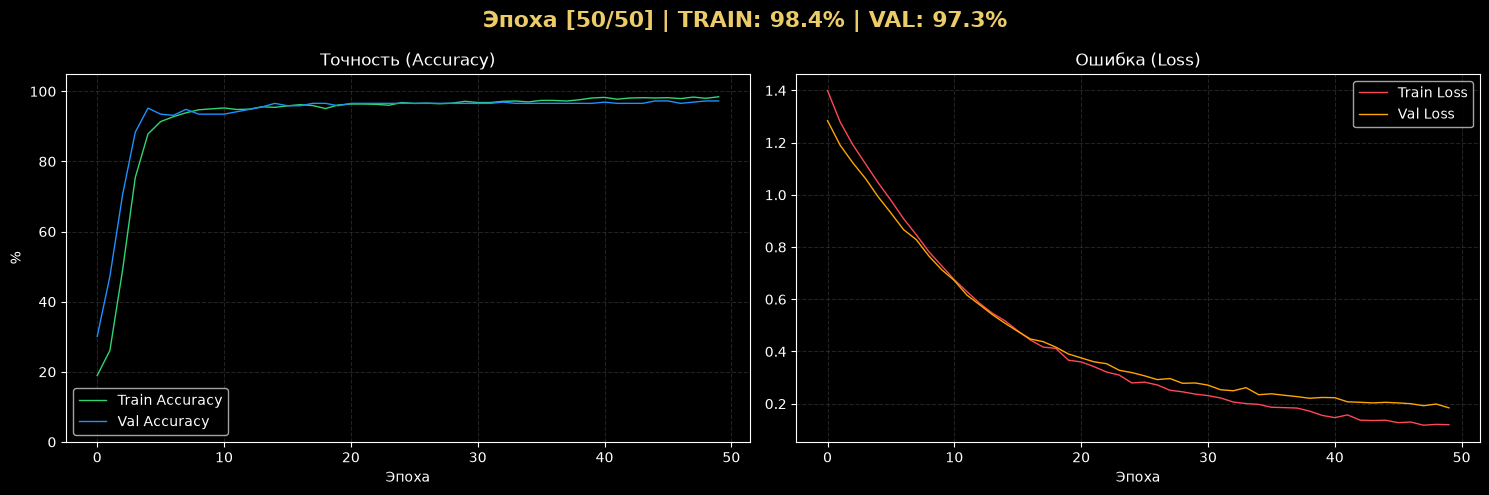

In [ ]:
import matplotlib.pyplot as plt
import torch
from IPython.display import clear_output

epochs = 50

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
model.to(device)
print(f"Обучаем на: {device}")

train_losses, val_losses = [], []
train_accs, val_accs = [], []

plt.style.use('dark_background')

for epoch in range(epochs):

    model.train()
    train_loss = 0
    correct_train = 0
    
    for batch_x, batch_y in train_dataloader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        optimizer.zero_grad()      
        outputs = model(batch_x)   
        loss = criterion(outputs, batch_y) 
        loss.backward()            
        optimizer.step()           
        
        train_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        correct_train += (predicted == batch_y).sum().item()
        
    acc_train = 100 * correct_train / len(train_dataloader.dataset)
    avg_train_loss = train_loss / len(train_dataloader)

    model.eval() 
    val_loss = 0
    correct_val = 0
    
    with torch.no_grad(): 
        for batch_x, batch_y in val_dataloader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)
            
            val_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            correct_val += (predicted == batch_y).sum().item()
            
    acc_val = 100 * correct_val / len(val_dataloader.dataset)
    avg_val_loss = val_loss / len(val_dataloader)
    
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_accs.append(acc_train)
    val_accs.append(acc_val)
    
    if (epoch + 1) % 2 == 0 or (epoch + 1) == epochs:
        clear_output(wait=True)
        
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
        fig.suptitle(f'Эпоха [{epoch+1}/{epochs}] | TRAIN: {acc_train:.1f}% | VAL: {acc_val:.1f}%', 
                     fontsize=16, fontweight='bold', color='#eccc68')
        
        # График точности (Accuracy)
        ax1.plot(train_accs, label='Train Accuracy', color='#2ed573', linewidth=1)
        ax1.plot(val_accs, label='Val Accuracy', color='#1e90ff', linewidth=1)
        ax1.set_title('Точность (Accuracy)')
        ax1.set_xlabel('Эпоха')
        ax1.set_ylabel('%')
        ax1.set_ylim(0, 105)
        ax1.legend()
        ax1.grid(color='#444', linestyle='--', alpha=0.5)
        
        # График ошибки (Loss)
        ax2.plot(train_losses, label='Train Loss', color='#ff4757', linewidth=1)
        ax2.plot(val_losses, label='Val Loss', color='#ffa502', linewidth=1)
        ax2.set_title('Ошибка (Loss)')
        ax2.set_xlabel('Эпоха')
        ax2.legend()
        ax2.grid(color='#444', linestyle='--', alpha=0.5)
        
        plt.tight_layout()
        plt.show()

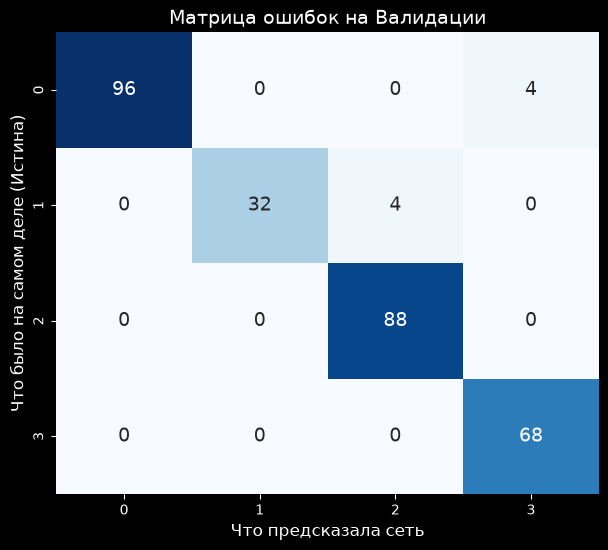

In [62]:
import torch
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

model.eval()
all_preds = []
all_labels = []

# Отключаем градиенты для ускорения и экономии памяти
with torch.no_grad():
    for batch_x, batch_y in val_dataloader:
        outputs = model(batch_x)
        _, predicted = torch.max(outputs.data, 1)
        
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(batch_y.cpu().numpy())

# Считаем матрицу
cm = confusion_matrix(all_labels, all_preds)

# Отрисовка
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, 
            annot_kws={"size": 14})

plt.xlabel('Что предсказала сеть', fontsize=12)
plt.ylabel('Что было на самом деле (Истина)', fontsize=12)
plt.title('Матрица ошибок на Валидации', fontsize=14)
plt.show()

Найдено ошибок 'Фон(0) -> Круг(3)': 4


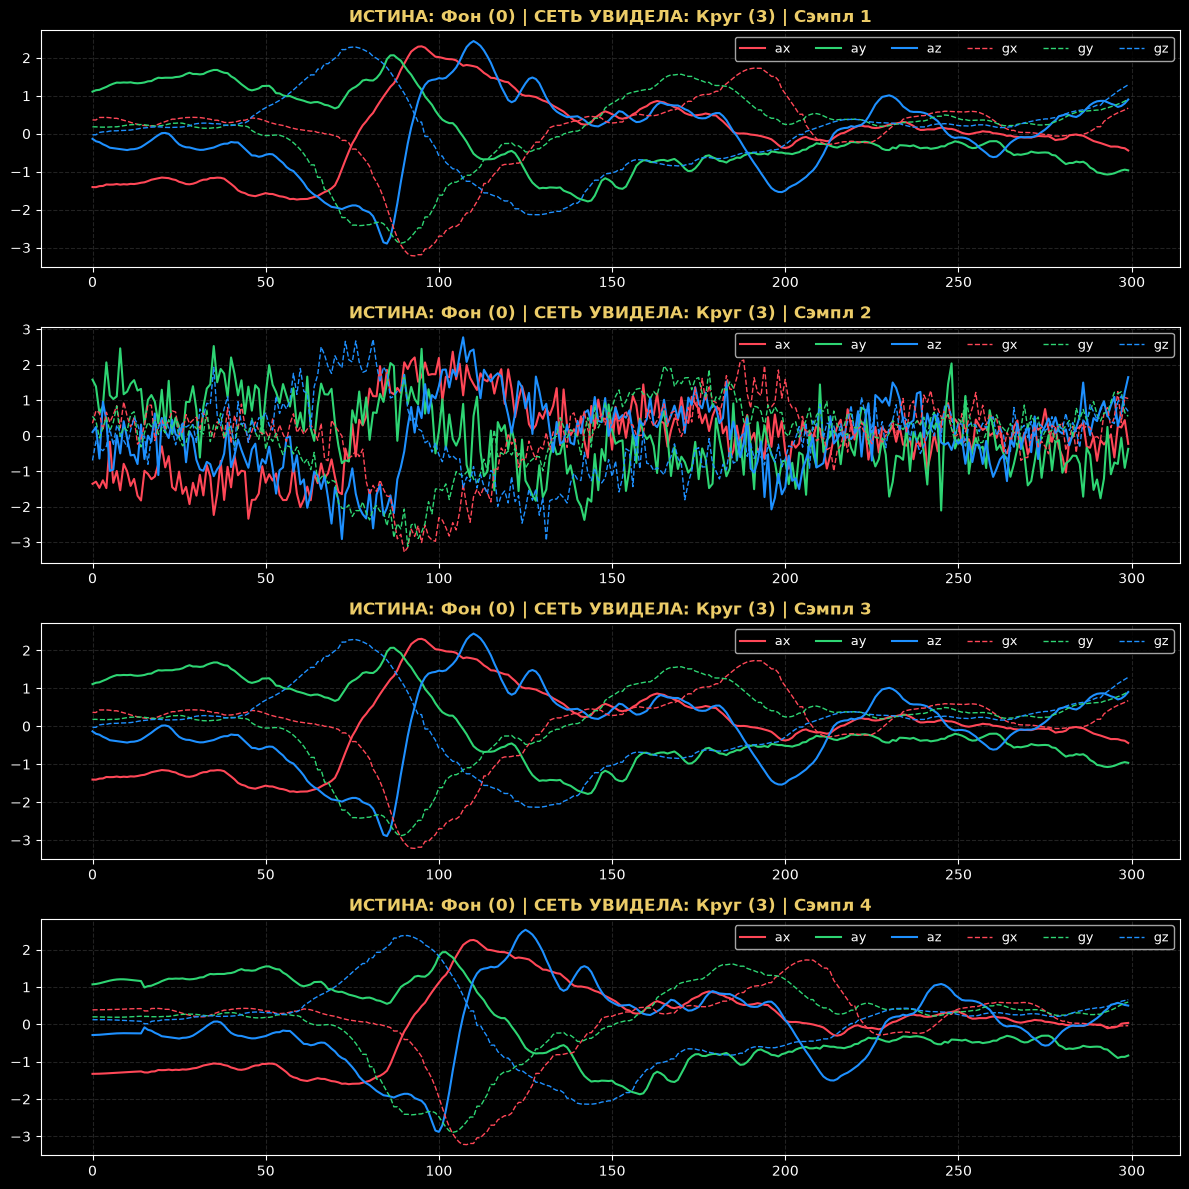


Найдено ошибок 'Telegram(1) -> Spotify(2)': 4


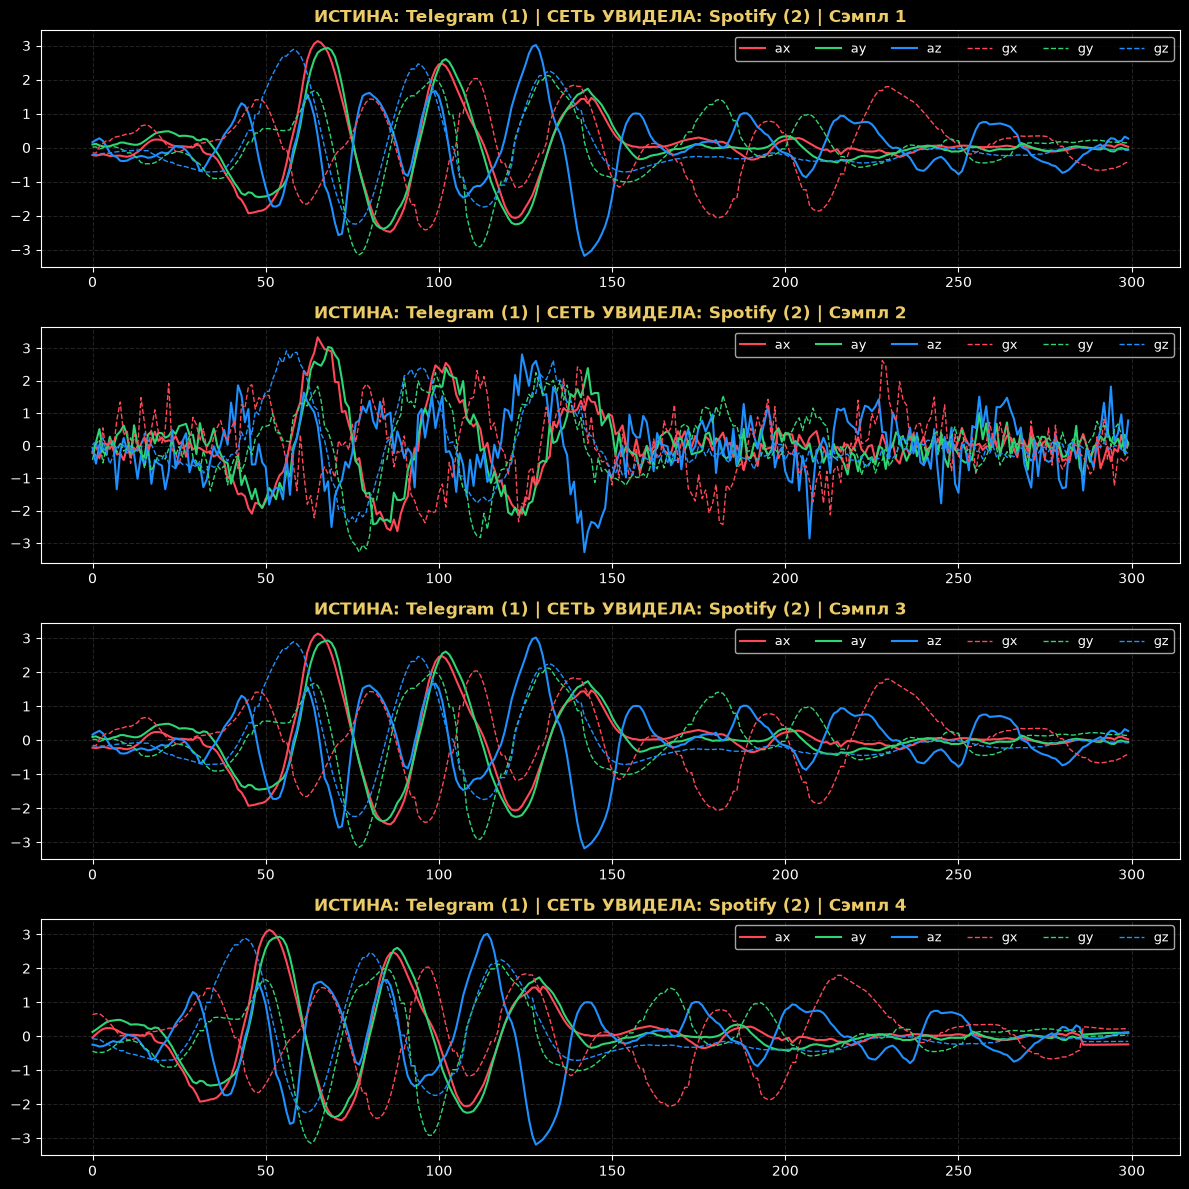

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()


errors_0_as_3 = [] # Истина: 0 (Фон), Предсказание: 3 (Круг)
errors_1_as_2 = [] # Истина: 1 (Telegram), Предсказание: 2 (Spotify)

# Прогоняем валидационную выборку
with torch.no_grad():
    for batch_x, batch_y in val_dataloader:
        batch_x = batch_x.to(device)
        outputs = model(batch_x)
        _, predicted = torch.max(outputs.data, 1)
        
        batch_x_cpu = batch_x.cpu().numpy()
        predicted_cpu = predicted.cpu().numpy()
        true_cpu = batch_y.cpu().numpy()
        
        # Ищем наши аномалии
        for i in range(len(true_cpu)):
            t = true_cpu[i]
            p = predicted_cpu[i]
            
            if t == 0 and p == 3:
                errors_0_as_3.append(batch_x_cpu[i])
            elif t == 1 and p == 2:
                errors_1_as_2.append(batch_x_cpu[i])

def plot_error_samples(samples, title_prefix):
    if not samples:
        print(f"Нет сэмплов для: {title_prefix}")
        return
        
    num_samples = len(samples)
    fig, axes = plt.subplots(num_samples, 1, figsize=(12, 3 * num_samples))
    if num_samples == 1:
        axes = [axes]
        
    plt.style.use('dark_background')
        
    for idx, ax in enumerate(axes):
        data = samples[idx] # Форма: (6, 300)
        
        # Акселерометр (сплошные линии)
        ax.plot(data[0], label='ax', color='#ff4757', linewidth=1.5)
        ax.plot(data[1], label='ay', color='#2ed573', linewidth=1.5)
        ax.plot(data[2], label='az', color='#1e90ff', linewidth=1.5)
        
        # Гироскоп (пунктир)
        ax.plot(data[3], label='gx', color='#ff4757', linestyle='--', linewidth=1)
        ax.plot(data[4], label='gy', color='#2ed573', linestyle='--', linewidth=1)
        ax.plot(data[5], label='gz', color='#1e90ff', linestyle='--', linewidth=1)
        
        ax.set_title(f"{title_prefix} | Сэмпл {idx+1}", color='#eccc68', fontweight='bold')
        ax.legend(loc='upper right', ncol=6, fontsize=9)
        ax.grid(color='#444', linestyle='--', alpha=0.5)
        
    plt.tight_layout()
    plt.show()

# Отрисовываем графики
print(f"Найдено ошибок 'Фон(0) -> Круг(3)': {len(errors_0_as_3)}")
plot_error_samples(errors_0_as_3, "ИСТИНА: Фон (0) | СЕТЬ УВИДЕЛА: Круг (3)")

print(f"\nНайдено ошибок 'Telegram(1) -> Spotify(2)': {len(errors_1_as_2)}")
plot_error_samples(errors_1_as_2, "ИСТИНА: Telegram (1) | СЕТЬ УВИДЕЛА: Spotify (2)")

In [64]:
# Подсчет общего числа обучаемых параметров
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"ОБЩЕЕ КОЛИЧЕСТВО ПАРАМЕТРОВ: {total_params:,}\n")
print("-" * 45)
print(f"{'Слой':<25} | {'Параметры'}")
print("-" * 45)

# Детализация по каждому слою
for name, param in model.named_parameters():
    if param.requires_grad:
        print(f"{name:<25} | {param.numel():,}")
print("-" * 45)

ОБЩЕЕ КОЛИЧЕСТВО ПАРАМЕТРОВ: 4,276

---------------------------------------------
Слой                      | Параметры
---------------------------------------------
features.0.weight         | 1,440
features.0.bias           | 16
features.1.weight         | 16
features.1.bias           | 16
features.4.weight         | 2,560
features.4.bias           | 32
features.5.weight         | 32
features.5.bias           | 32
classifier.weight         | 128
classifier.bias           | 4
---------------------------------------------


In [66]:
import numpy as np

model.eval()
weights = {}

# Вытаскиваем все матрицы весов и смещений из PyTorch
for name, tensor in model.state_dict().items():
    weights[name] = tensor.cpu().numpy()

# Сохраняем в обычный numpy-архив
np.savez('weights.npz', **weights)